
# LPU Student Academic Early-Warning System

## Project Overview
A Machine Learning-based system to identify students who may be at academic risk.

## Objectives
- Analyze student academic performance.
- Clean and preprocess the dataset.
- Perform Exploratory Data Analysis.
- Create visualizations using Seaborn and Matplotlib.
- Train Machine Learning models.
- Evaluate model performance.

## Dataset
UCI Student Performance Dataset

## Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

## Machine Learning Models
Logistic Regression and Random Forest

## Target
Academic Risk: Final Grade (G3) < 10




In [5]:

# Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:
# Load Dataset

data_path = "data/student-mat.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [7]:
# Dataset Overview

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of Rows: 395
Number of Columns: 33

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null  

In [8]:
# Check Missing Values

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total Missing Values:
0


In [9]:
# Check Duplicate Records

duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

Total Duplicate Records: 0


In [10]:
# Remove Duplicate Records

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)
print("Total Duplicate Records:", df.duplicated().sum())

Dataset shape after removing duplicates: (395, 33)
Total Duplicate Records: 0


In [11]:
# Create Academic Risk Target

df["academic_risk"] = (df["G3"] < 10).astype(int)

print("Academic Risk Target Created!")

print("\nRisk Distribution:")
print(df["academic_risk"].value_counts())

print("\nRisk Percentage:")
print(df["academic_risk"].value_counts(normalize=True) * 100)


Academic Risk Target Created!

Risk Distribution:
academic_risk
0    265
1    130
Name: count, dtype: int64

Risk Percentage:
academic_risk
0    67.088608
1    32.911392
Name: proportion, dtype: float64


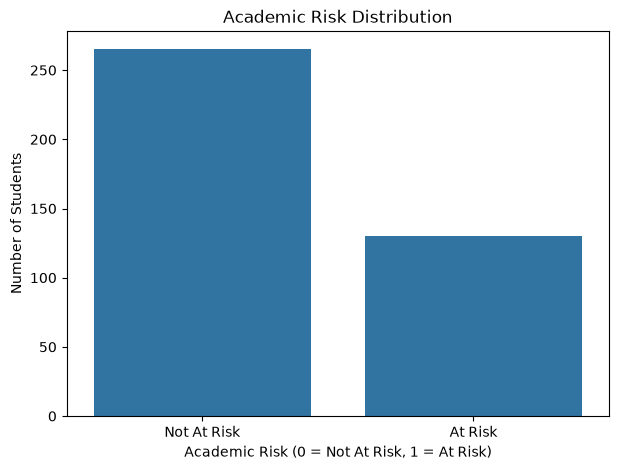

In [12]:
# Academic Risk Distribution

risk_counts = df["academic_risk"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values
)

plt.title("Academic Risk Distribution")
plt.xlabel("Academic Risk (0 = Not At Risk, 1 = At Risk)")
plt.ylabel("Number of Students")

plt.xticks([0, 1], ["Not At Risk", "At Risk"])

plt.show()

In [13]:
# Academic Risk Percentage

total_students = len(df)

at_risk_students = df["academic_risk"].sum()

risk_percentage = (at_risk_students / total_students) * 100

print("Total Students:", total_students)
print("At-Risk Students:", at_risk_students)
print("Academic Risk Percentage:", round(risk_percentage, 2), "%")

Total Students: 395
At-Risk Students: 130
Academic Risk Percentage: 32.91 %


In [14]:
# Grade Analysis

print("Average G1 Grade:", round(df["G1"].mean(), 2))
print("Average G2 Grade:", round(df["G2"].mean(), 2))
print("Average G3 Grade:", round(df["G3"].mean(), 2))

print("\nMinimum G3 Grade:", df["G3"].min())
print("Maximum G3 Grade:", df["G3"].max())

Average G1 Grade: 10.91
Average G2 Grade: 10.71
Average G3 Grade: 10.42

Minimum G3 Grade: 0
Maximum G3 Grade: 20


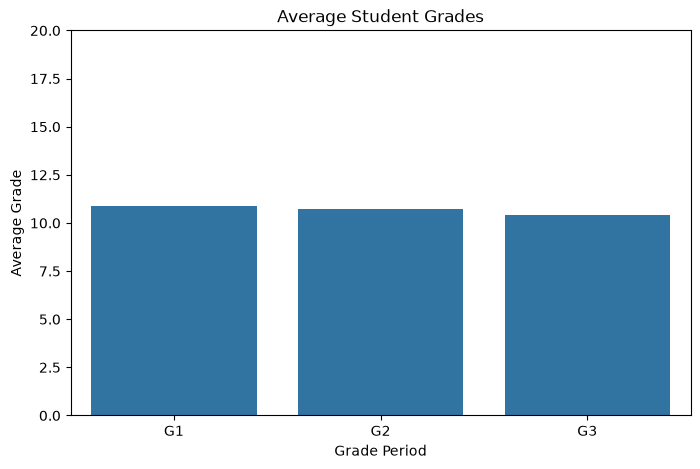

In [15]:
# Average Grade Analysis

grades = ["G1", "G2", "G3"]

average_grades = [
    df["G1"].mean(),
    df["G2"].mean(),
    df["G3"].mean()
]

plt.figure(figsize=(8, 5))

sns.barplot(
    x=grades,
    y=average_grades
)

plt.title("Average Student Grades")
plt.xlabel("Grade Period")
plt.ylabel("Average Grade")

plt.ylim(0, 20)

plt.show()

In [16]:
# Compare Grades by Academic Risk

risk_grade_analysis = df.groupby("academic_risk")[["G1", "G2", "G3"]].mean()

print("Average Grades by Academic Risk:")
display(risk_grade_analysis)

Average Grades by Academic Risk:


,G1,G2,G3
academic_risk,,,
0,12.452830,12.622642,12.883019
1,7.761538,6.823077,5.384615


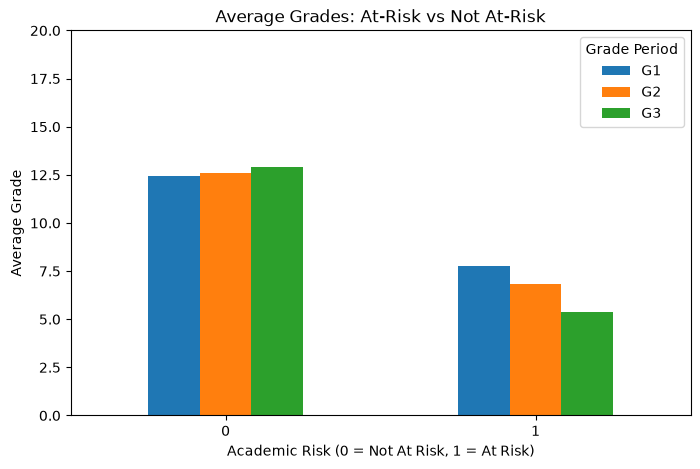

In [17]:
# Compare Average Grades by Academic Risk

risk_grade_analysis = df.groupby("academic_risk")[["G1", "G2", "G3"]].mean()

risk_grade_analysis.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Grades: At-Risk vs Not At-Risk")
plt.xlabel("Academic Risk (0 = Not At Risk, 1 = At Risk)")
plt.ylabel("Average Grade")

plt.xticks(rotation=0)
plt.ylim(0, 20)

plt.legend(title="Grade Period")
plt.show()

In [18]:
# Grade Correlation Analysis

grade_correlation = df[["G1", "G2", "G3"]].corr()

print("Grade Correlation:")
display(grade_correlation)

Grade Correlation:


,G1,G2,G3
G1,1.000000,0.852118,0.801468
G2,0.852118,1.000000,0.904868
G3,0.801468,0.904868,1.000000


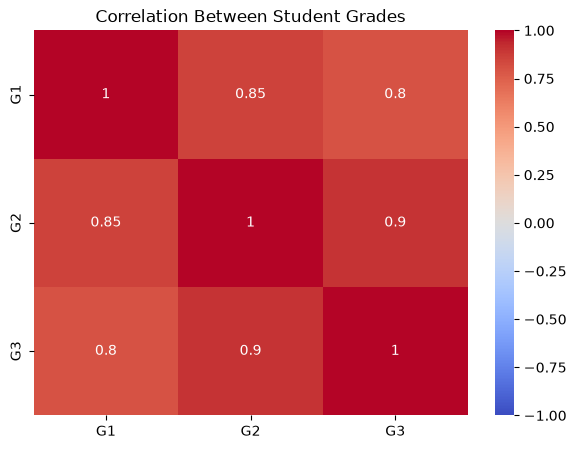

In [19]:
# Grade Correlation Heatmap

grade_correlation = df[["G1", "G2", "G3"]].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    grade_correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Student Grades")

plt.show()

In [20]:
# Numerical Features Summary

numerical_summary = df.describe()

display(numerical_summary)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,academic_risk
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190,0.329114
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443,0.470487
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000,0.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000,0.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000,1.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000,1.000000


In [21]:
# Categorical Features Summary

categorical_columns = df.select_dtypes(include="object").columns

print("Total Categorical Columns:", len(categorical_columns))

print("\nCategorical Column Names:")
print(categorical_columns.tolist())

Total Categorical Columns: 17

Categorical Column Names:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [22]:
# Categorical Features Analysis

categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print("\nColumn:", column)
    print(df[column].value_counts())


Column: school
school
GP    349
MS     46
Name: count, dtype: int64

Column: sex
sex
F    208
M    187
Name: count, dtype: int64

Column: address
address
U    307
R     88
Name: count, dtype: int64

Column: famsize
famsize
GT3    281
LE3    114
Name: count, dtype: int64

Column: Pstatus
Pstatus
T    354
A     41
Name: count, dtype: int64

Column: Mjob
Mjob
other       141
services    103
at_home      59
teacher      58
health       34
Name: count, dtype: int64

Column: Fjob
Fjob
other       217
services    111
teacher      29
at_home      20
health       18
Name: count, dtype: int64

Column: reason
reason
course        145
home          109
reputation    105
other          36
Name: count, dtype: int64

Column: guardian
guardian
mother    273
father     90
other      32
Name: count, dtype: int64

Column: schoolsup
schoolsup
no     344
yes     51
Name: count, dtype: int64

Column: famsup
famsup
yes    242
no     153
Name: count, dtype: int64

Column: paid
paid
no     214
yes    181
Name

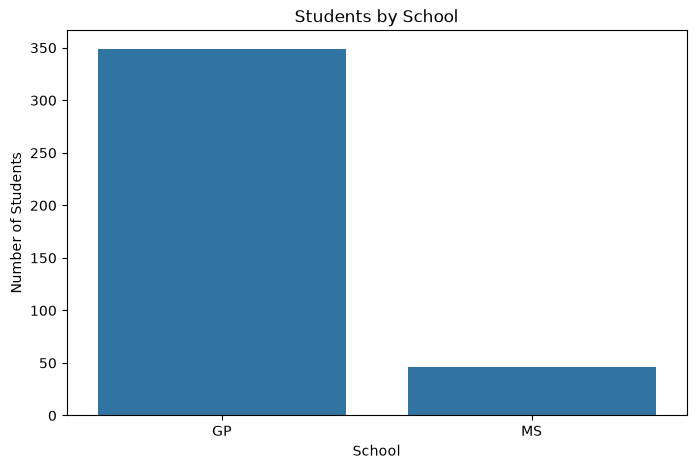

In [23]:

# Categorical Features Visualization

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="school"
)

plt.title("Students by School")
plt.xlabel("School")
plt.ylabel("Number of Students")

plt.show()

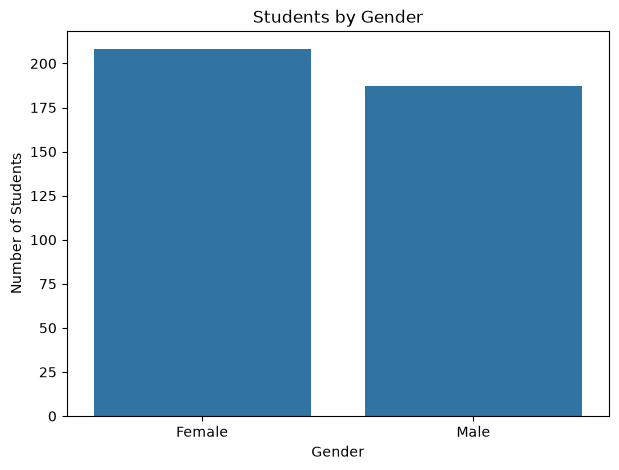

In [24]:
# Students by Gender

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sex"
)

plt.title("Students by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Students")

plt.xticks([0, 1], ["Female", "Male"])

plt.show()

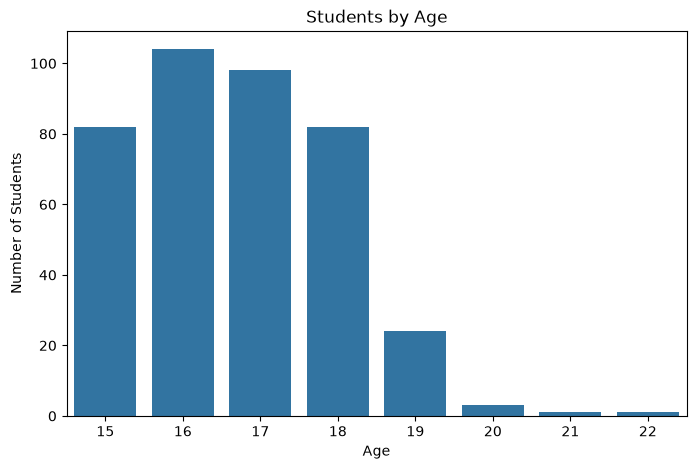

In [25]:
# Students by Age

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="age"
)

plt.title("Students by Age")
plt.xlabel("Age")
plt.ylabel("Number of Students")

plt.show()

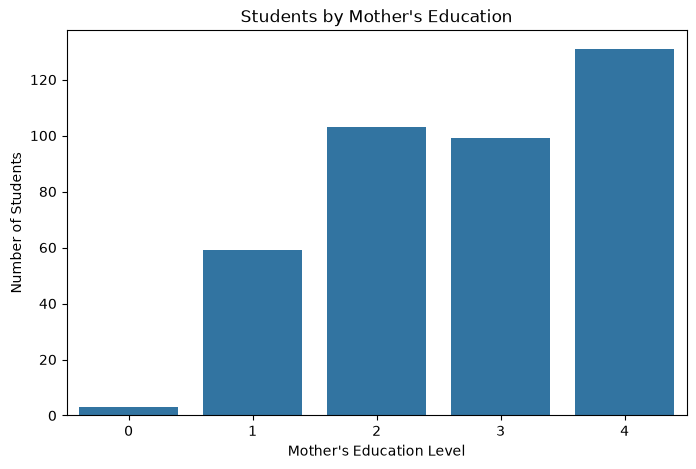

In [26]:
# Students by Mother's Education

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Medu"
)

plt.title("Students by Mother's Education")
plt.xlabel("Mother's Education Level")
plt.ylabel("Number of Students")

plt.show()

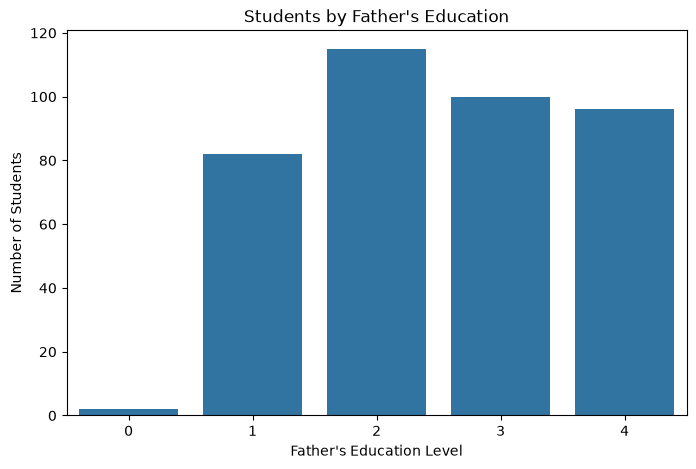

In [27]:
# Students by Father's Education

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Fedu"
)

plt.title("Students by Father's Education")
plt.xlabel("Father's Education Level")
plt.ylabel("Number of Students")

plt.show()

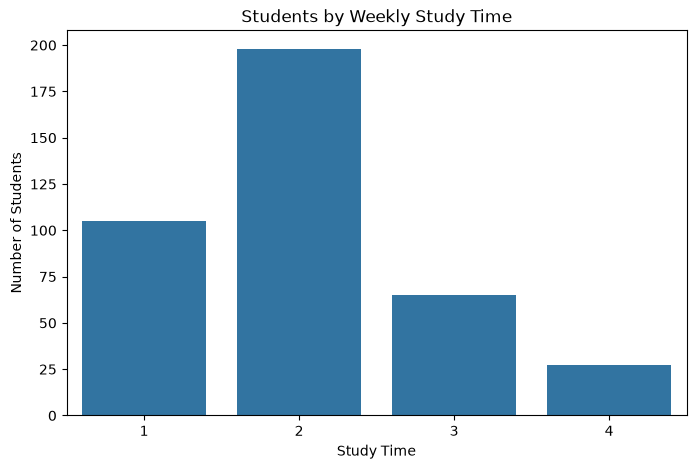

In [28]:
# Students by Study Time

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="studytime"
)

plt.title("Students by Weekly Study Time")
plt.xlabel("Study Time")
plt.ylabel("Number of Students")

plt.show()

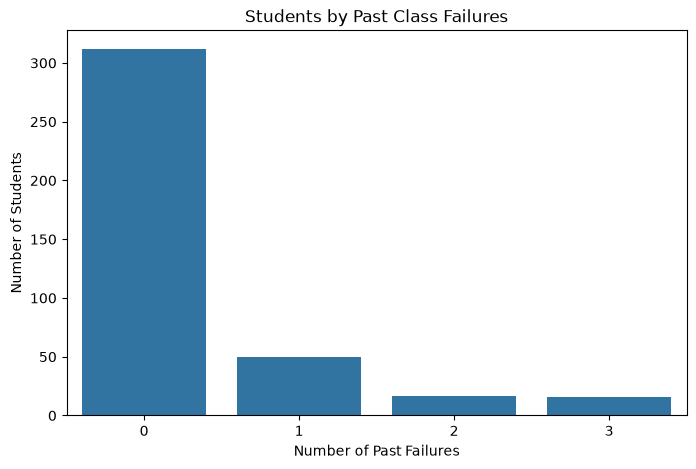

In [29]:
# Students by Past Failures

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="failures"
)

plt.title("Students by Past Class Failures")
plt.xlabel("Number of Past Failures")
plt.ylabel("Number of Students")

plt.show()

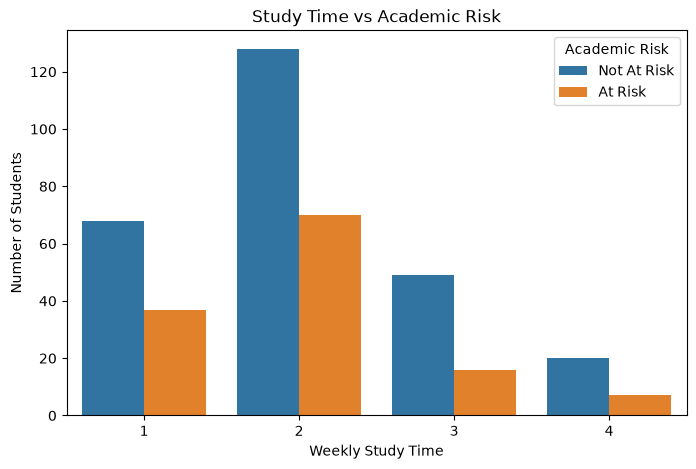

In [30]:
# Study Time vs Academic Risk

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="studytime",
    hue="academic_risk"
)

plt.title("Study Time vs Academic Risk")
plt.xlabel("Weekly Study Time")
plt.ylabel("Number of Students")

plt.legend(
    title="Academic Risk",
    labels=["Not At Risk", "At Risk"]
)

plt.show()

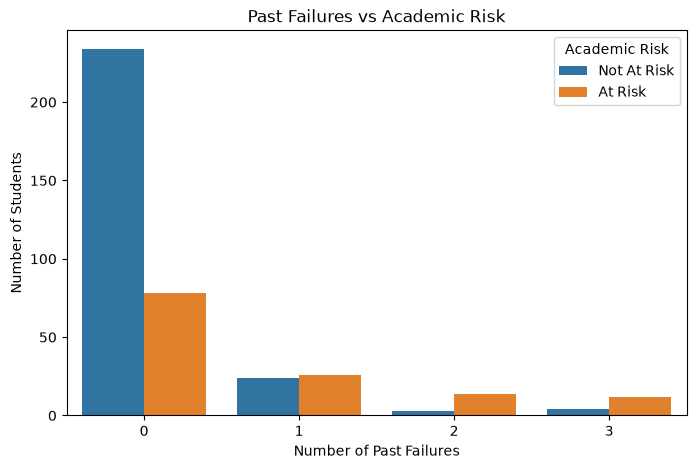

In [31]:
# Past Failures vs Academic Risk

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="failures",
    hue="academic_risk"
)

plt.title("Past Failures vs Academic Risk")
plt.xlabel("Number of Past Failures")
plt.ylabel("Number of Students")

plt.legend(
    title="Academic Risk",
    labels=["Not At Risk", "At Risk"]
)

plt.show()

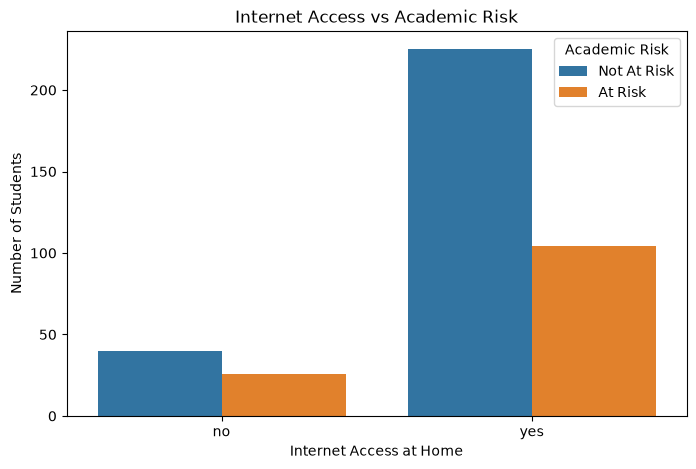

In [32]:
# Internet Access vs Academic Risk

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="internet",
    hue="academic_risk"
)

plt.title("Internet Access vs Academic Risk")
plt.xlabel("Internet Access at Home")
plt.ylabel("Number of Students")

plt.legend(
    title="Academic Risk",
    labels=["Not At Risk", "At Risk"]
)

plt.show()

In [33]:
# Feature Selection

target_column = "academic_risk"

X = df.drop(
    columns=["G2", "G3", "academic_risk"]
)

y = df[target_column]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSelected Features:")
print(X.columns.tolist())

Input Features Shape: (395, 31)
Target Shape: (395,)

Selected Features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1']


In [34]:
# Separate Numerical and Categorical Features

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

print("Total Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Total Numerical Features: 14
Total Categorical Features: 17

Numerical Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1']

Categorical Features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [35]:
# Import Preprocessing Tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Preprocessing tools imported successfully!")

Preprocessing tools imported successfully!


In [36]:
# Import Preprocessing Tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Preprocessing tools imported successfully!")

Preprocessing tools imported successfully!


In [37]:
# Feature Selection

target_column = "academic_risk"

X = df.drop(
    columns=["G2", "G3", "academic_risk"]
)

y = df[target_column]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (395, 31)
Target Shape: (395,)


In [39]:
# Create Preprocessing Pipeline

numerical_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [41]:
# Complete Model Training and Prediction

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Feature Selection
X = df.drop(columns=["G2", "G3", "academic_risk"])
y = df["academic_risk"]

# Separate Features
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create Model
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train Model
rf_model.fit(X_train, y_train)

# Predictions
y_pred = rf_model.predict(X_test)

print("Model Trained Successfully!")
print("Predictions Generated Successfully!")

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Model Trained Successfully!
Predictions Generated Successfully!

Training Data: (316, 31)
Testing Data: (79, 31)

First 10 Actual Values:
[1 0 0 1 1 0 0 0 1 0]

First 10 Predicted Values:
[1 0 1 1 1 0 0 0 1 0]


In [42]:
# Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Model Performance")
print("-------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Performance
-------------------------
Accuracy: 81.01 %
Precision: 68.97 %
Recall: 76.92 %
F1 Score: 72.73 %

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.83      0.85        53
           1       0.69      0.77      0.73        26

    accuracy                           0.81        79
   macro avg       0.78      0.80      0.79        79
weighted avg       0.82      0.81      0.81        79



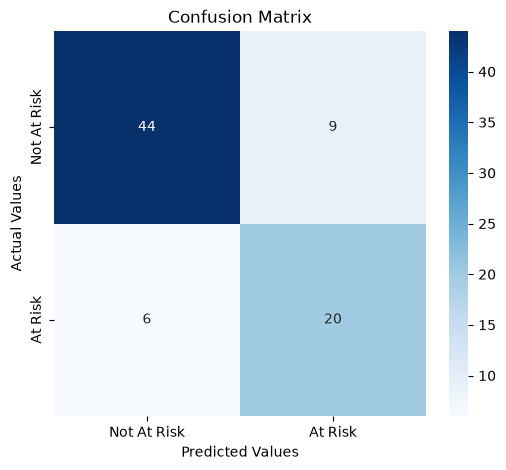

In [43]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not At Risk", "At Risk"],
    yticklabels=["Not At Risk", "At Risk"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [44]:
# Save Final Model

import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(rf_model, "models/academic_risk_model.pkl")

print("Model Saved Successfully!")
print("File Location: models/academic_risk_model.pkl")

Model Saved Successfully!
File Location: models/academic_risk_model.pkl


In [45]:
# Feature Importance

feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

importances = rf_model.named_steps["classifier"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

Top 10 Important Features:


,Feature,Importance
13,num__G1,0.304072
12,num__absences,0.048023
5,num__failures,0.040513
8,num__goout,0.033295
0,num__age,0.031477
6,num__famrel,0.026468
10,num__Walc,0.025827
7,num__freetime,0.025733
11,num__health,0.025046
1,num__Medu,0.023416


In [46]:
# Cross Validation

from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="recall"
)

print("Recall Scores:", cv_scores)
print("Average Recall:", round(cv_scores.mean() * 100, 2), "%")
print("Standard Deviation:", round(cv_scores.std() * 100, 2), "%")

Recall Scores: [0.65384615 0.76923077 0.69230769 0.88461538 0.88461538]
Average Recall: 77.69 %
Standard Deviation: 9.55 %


In [47]:
# Random Forest Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    rf_model,
    param_grid,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Recall:")
print(round(grid_search.best_score_ * 100, 2), "%")

Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Best Cross-Validation Recall:
80.62 %


In [48]:
# Evaluate Best Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

best_y_pred = best_model.predict(X_test)

print("Best Model Performance")
print("--------------------------")

print("Accuracy:", round(accuracy_score(y_test, best_y_pred) * 100, 2), "%")

print("Precision:", round(precision_score(y_test, best_y_pred) * 100, 2), "%")

print("Recall:", round(recall_score(y_test, best_y_pred) * 100, 2), "%")

print("F1 Score:", round(f1_score(y_test, best_y_pred) * 100, 2), "%")

Best Model Performance
--------------------------
Accuracy: 81.01 %
Precision: 66.67 %
Recall: 84.62 %
F1 Score: 74.58 %


In [49]:
# Save Final Tuned Model

import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(best_model, "models/academic_risk_model.pkl")

print("Final Tuned Model Saved Successfully!")
print("Location: models/academic_risk_model.pkl")

Final Tuned Model Saved Successfully!
Location: models/academic_risk_model.pkl


In [4]:
df = pd.read_csv("data/student-mat.csv", sep=",")

print(df.shape)
print(df.columns.tolist())

(395, 33)
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [5]:

import pandas as pd
import numpy as np
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

df = pd.read_csv("data/student-mat.csv", sep=",")

df["academic_risk"] = (df["G3"] < 10).astype(int)

df["academic_percentage"] = (df["G1"] / 20) * 100

df["attendance_percentage"] = (
    100 - df["absences"]
).clip(0, 100)

X = df[["age", "academic_percentage", "attendance_percentage"]]
y = df["academic_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, y_pred) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Path("models").mkdir(exist_ok=True)

joblib.dump(
    best_model,
    "models/academic_risk_model_3features.pkl"
)

print("\n3-Feature Model Saved Successfully!")

Best Parameters: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 200}
Accuracy: 86.08 %
Precision: 75.86 %
Recall: 84.62 %
F1 Score: 80.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.87      0.89        53
           1       0.76      0.85      0.80        26

    accuracy                           0.86        79
   macro avg       0.84      0.86      0.85        79
weighted avg       0.87      0.86      0.86        79


Confusion Matrix:
[[46  7]
 [ 4 22]]

3-Feature Model Saved Successfully!


In [3]:
print(df.shape)
print(df.columns.tolist())

(395, 1)
['school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3']
